# Conditional VAE for MNIST

The encoder receives a flattened image $x$ and the one-hot digit condition $c$. It predicts the mean $\mu$ and log variance $\log \sigma^2$ of the diagonal Gaussian $q(z\mid x,c)$. Reparameterization uses $z=\mu+\exp(0.5\,\log\sigma^2)\odot\epsilon$, with $\epsilon\sim\mathcal N(0,I)$, so gradients flow through the mean and scale.

The decoder receives $z$ concatenated with the same condition $c$ and outputs one logit per pixel. Every class shares the prior $p(z)=\mathcal N(0,I)$. The objective adds pixelwise BCE with logits to $\beta$ times the analytical Gaussian KL divergence. BCE is summed over pixels, KL is summed over latent dimensions, and both sums are averaged across images. The default is $\beta=1$.

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import torch

# In Google Colab uncomment these lines:
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/models.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/plots.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/training.py

from plots import image_grid, learning_curves
from training import Settings, fit_or_load, loader, mnist, setup, split_train

quick = os.getenv("VAE_QUICK", "0") == "1"
settings = Settings(quick=quick, epochs=1 if quick else 15)
device = setup(settings)
mode = "QUICK MODE (smoke test)" if quick else "Full experiment"
print(f"{mode} | device={device} | {settings}")

Full experiment | device=cuda | Settings(seed=42, latent_dim=16, hidden_dim=256, batch_size=256, epochs=15, learning_rate=0.001, beta=1.0, quick=False)


## Fit and inspect learning curves

The model uses one hidden layer on each side. Change the settings in the first cell to explore latent dimension, learning rate, or beta. The checkpoint keeps the epoch with lowest validation total loss.

Epoch  1 | train {'total': 205.03211975097656, 'reconstruction': 193.2935028076172, 'kl': 11.738690376281738} | validation {'total': 153.03738403320312, 'reconstruction': 139.38746643066406, 'kl': 13.649930953979492}


Epoch  2 | train {'total': 139.46615600585938, 'reconstruction': 123.3892822265625, 'kl': 16.076841354370117} | validation {'total': 131.4374542236328, 'reconstruction': 114.3388442993164, 'kl': 17.09859275817871}


Epoch  3 | train {'total': 125.9747314453125, 'reconstruction': 107.85074615478516, 'kl': 18.12396240234375} | validation {'total': 123.3466567993164, 'reconstruction': 104.9468994140625, 'kl': 18.399763107299805}


Epoch  4 | train {'total': 119.88406372070312, 'reconstruction': 100.88141632080078, 'kl': 19.002662658691406} | validation {'total': 118.78129577636719, 'reconstruction': 99.59425354003906, 'kl': 19.18705177307129}


Epoch  5 | train {'total': 116.3702163696289, 'reconstruction': 96.9248046875, 'kl': 19.445432662963867} | validation {'total': 115.91602325439453, 'reconstruction': 96.25226593017578, 'kl': 19.663766860961914}


Epoch  6 | train {'total': 113.980712890625, 'reconstruction': 94.23094177246094, 'kl': 19.749828338623047} | validation {'total': 114.07129669189453, 'reconstruction': 94.09766387939453, 'kl': 19.97365951538086}


... (5 outputs left out)

Epoch 12 | train {'total': 106.95697021484375, 'reconstruction': 86.65496826171875, 'kl': 20.301992416381836} | validation {'total': 107.62950897216797, 'reconstruction': 87.71944427490234, 'kl': 19.910051345825195}


Epoch 13 | train {'total': 106.30883026123047, 'reconstruction': 86.0049819946289, 'kl': 20.303813934326172} | validation {'total': 107.04004669189453, 'reconstruction': 86.3584213256836, 'kl': 20.681625366210938}


Epoch 14 | train {'total': 105.76801300048828, 'reconstruction': 85.45601654052734, 'kl': 20.312030792236328} | validation {'total': 106.56986999511719, 'reconstruction': 86.09793853759766, 'kl': 20.4719295501709}


Epoch 15 | train {'total': 105.2480239868164, 'reconstruction': 84.92552185058594, 'kl': 20.322467803955078} | validation {'total': 106.2094955444336, 'reconstruction': 85.28546905517578, 'kl': 20.924015045166016}
Saved runs\conditional-full-656d54714574.pt (epoch 15)


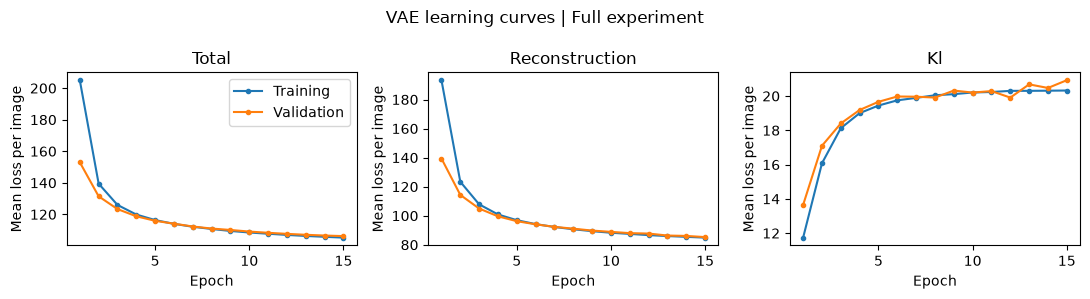

In [ ]:
train, validation, _ = split_train(mnist(), settings)
model, history = fit_or_load(settings, train, validation, device, conditional=True)
learning_curves(history, mode)

## Reconstruct held-out images

Reconstruction starts with an observed image and encodes it to the posterior mean. Decoding the mean gives a deterministic view of its reconstruction. Training samples from the posterior to optimize the expected reconstruction term. Sigmoid converts decoder logits to pixel intensities for display.

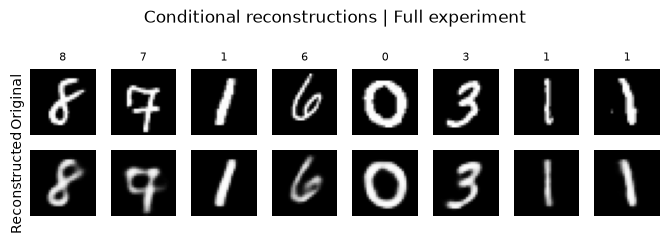

In [ ]:
images, digit_ids = next(iter(loader(validation, settings)))
images = images[:8].to(device)
digit_ids = digit_ids[:8].to(device)
with torch.inference_mode():
    mu, _ = model.encode(images, digit_ids)
    restored = model.decode(mu, digit_ids).sigmoid()
image_grid(
    torch.stack((images, restored)).cpu().numpy(),
    f"Conditional reconstructions | {mode}",
    row_labels=["Original", "Reconstructed"],
    column_labels=digit_ids.tolist(),
)

## Generate new digits

Generation starts from the Gaussian prior. The decoder already has both inputs it needs, so the encoder is unnecessary. Changing the class requests a different digit. Changing the latent vector at a fixed class can vary properties like stroke thickness and slant. The learned decoder can combine these inputs nonlinearly, so a shared latent vector does not guarantee that every digit preserves exactly the same style.

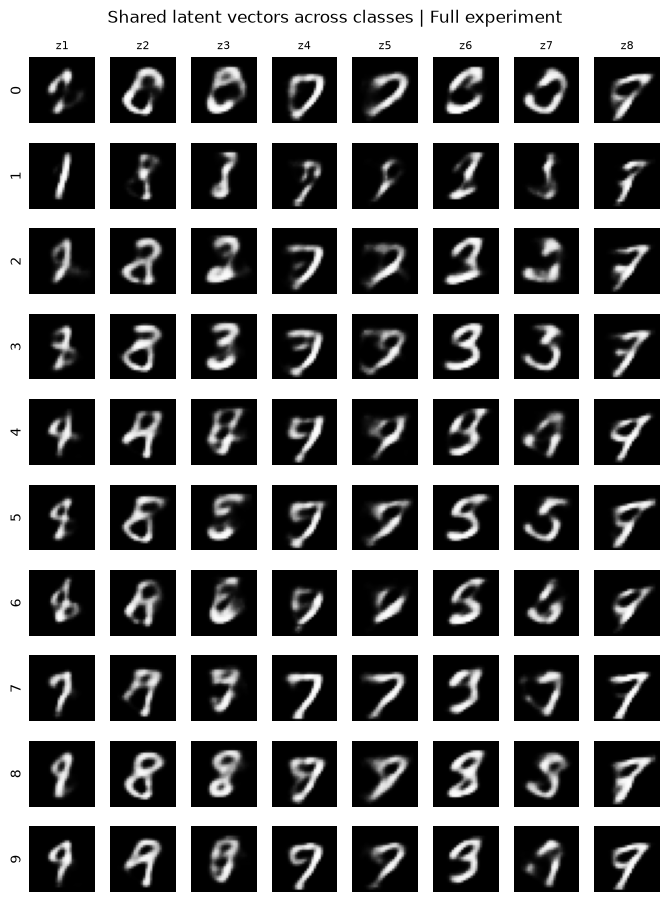

In [ ]:
rng = torch.Generator(device=device).manual_seed(settings.seed + 10)
columns = 8
z = torch.randn(columns, settings.latent_dim, generator=rng, device=device)
labels = torch.arange(10, device=device).repeat_interleave(columns)
with torch.inference_mode():
    samples = model.decode(z.repeat(10, 1), labels).sigmoid()
image_grid(
    samples.cpu().numpy().reshape(10, columns, 28, 28),
    f"Shared latent vectors across classes | {mode}",
    row_labels=list(range(10)),
    column_labels=[f"z{i + 1}" for i in range(columns)],
)

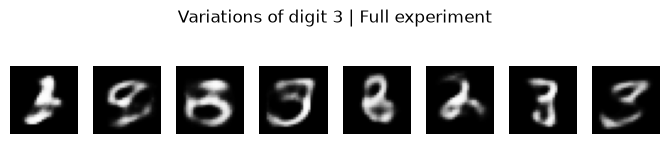

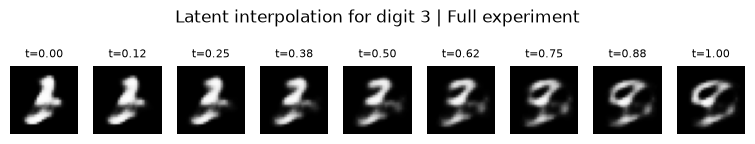

In [ ]:
digit = 3
variants = torch.randn(8, settings.latent_dim, generator=rng, device=device)
weights = torch.linspace(0, 1, 9, device=device)
path = torch.lerp(variants[0], variants[1], weights[:, None])
with torch.inference_mode():
    variations = model.decode(variants, torch.full((len(variants),), digit, device=device)).sigmoid()
    interpolated = model.decode(path, torch.full((len(path),), digit, device=device)).sigmoid()
image_grid(variations.cpu().numpy()[None], f"Variations of digit {digit} | {mode}")
image_grid(
    interpolated.cpu().numpy()[None],
    f"Latent interpolation for digit {digit} | {mode}",
    column_labels=[f"t={t:.2f}" for t in weights.tolist()],
)